# 4채널 확인 — 채널 짝과 전송 (Step8e)

> 2026-10-29 녹음 `ch4_map` (펌웨어 4채널 첫 녹음) · 커널: `Tools/.venv` · 그림은 끝(4절)에 한 장 (GUIDE v2.7)

**질문:** 펌웨어가 꺼낸 ch1 ~ ch4가 배선한 마이크와 맞나? (MIC1 0° = A0, MIC2 120° = A1, MIC3 −120° = A5, MIC4 통 위 = A2)
**방법:** 사용자가 MIC1 → MIC2 → MIC3 → MIC4 순서로 마이크 바로 옆에서 손가락을 3번씩 튕겼다. 튕김마다 가장 큰 채널을 찾는다. 바로 옆 소리는 그 마이크에서 가장 크다 (거리 1 ~ 2 cm 대 7 cm 이상).
**함께 보는 것:** 유실·CRC·클리핑, 전송 속도, CPU.

In [1]:
import json, sys
import numpy as np, soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.signal import butter, sosfiltfilt
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
D = "../dumps/stream/ch4_map"
S = json.load(open(f"{D}/summary.json", encoding="utf-8"))
x, FS = sf.read(f"{D}/seg_000.wav", dtype="float64"); x = (x - x.mean(0)).T
print(f"채널 {x.shape[0]}개 · {x.shape[1] / FS:.1f} s · fs {FS} Hz")
print("유실·OVR·CRC:", S["criteria"], "· CPU 최대", S["cpu_max_pct"], "% · 패킷", S["packets"]["packets"], "· 클리핑 패킷", S["packets"]["clip_packets"])

채널 4개 · 46.1 s · fs 12500 Hz
유실·OVR·CRC: {'loss': True, 'ovr': True, 'crc': True, 'clip': False, 'time_restore': True} · CPU 최대 53 % · 패킷 2249 · 클리핑 패킷 9


## 1. 20 ms 창 에너지와 튕김 찾기

300 ~ 3000 Hz로 거른 뒤 20 ms 창마다 채널별 에너지 [dB]. 네 채널 중 최대가 조용한 바닥(중앙값)보다 20 dB 넘게 큰 창을 튕김 후보로 보고, 0.3 s 안에 붙은 창은 한 번으로 묶는다.

In [2]:
sos = butter(4, [300, 3000], "bandpass", fs=FS, output="sos")
y = sosfiltfilt(sos, x, axis=1)
W = int(0.02 * FS); n = y.shape[1] // W
E = 10 * np.log10(np.mean(y[:, :n * W].reshape(4, n, W) ** 2, axis=2) + 1e-20)   # [4, n]
t = (np.arange(n) + 0.5) * W / FS
floor = np.median(E, axis=1)
hot = np.flatnonzero(E.max(0) > floor.max() + 20)
events = []
for i in hot:
    if events and t[i] - t[events[-1][-1]] < 0.3: events[-1].append(i)
    else: events.append([i])
print("바닥 [dB]:", np.round(floor, 1), "· 튕김 후보", len(events), "개")

바닥 [dB]: [-66.4 -64.3 -59.  -62.7] · 튕김 후보 12 개


## 2. 튕김마다 가장 큰 채널

각 튕김의 최고 에너지 창에서 채널별 에너지와, 1등과 2등의 차이 [dB].

In [3]:
rows = []
for k, ev in enumerate(events):
    i = ev[int(np.argmax(E[:, ev].max(0)))]
    e = E[:, i]; o = np.argsort(e)[::-1]
    rows.append((t[i], o[0] + 1, e[o[0]] - e[o[1]], e))
    print(f"{k + 1:2d}. {t[i]:6.2f} s  가장 큼 ch{o[0] + 1}  (2등 ch{o[1] + 1}보다 {e[o[0]] - e[o[1]]:4.1f} dB)  ch1~4 " + " ".join(f"{v:6.1f}" for v in e))
seq = [r[1] for r in rows]
print("순서:", seq)

 1.  11.41 s  가장 큼 ch1  (2등 ch3보다  1.4 dB)  ch1~4  -14.1  -15.7  -15.5  -17.7
 2.  13.45 s  가장 큼 ch1  (2등 ch3보다  3.6 dB)  ch1~4  -15.4  -20.1  -19.0  -20.7
 3.  15.59 s  가장 큼 ch1  (2등 ch3보다  2.7 dB)  ch1~4  -14.6  -18.3  -17.3  -20.2
 4.  19.55 s  가장 큼 ch2  (2등 ch3보다  6.3 dB)  ch1~4  -33.1  -20.1  -26.4  -35.6
 5.  21.31 s  가장 큼 ch2  (2등 ch3보다  3.2 dB)  ch1~4  -35.2  -24.6  -27.9  -32.5
 6.  23.41 s  가장 큼 ch2  (2등 ch3보다  2.2 dB)  ch1~4  -36.1  -23.5  -25.7  -30.6
 7.  27.47 s  가장 큼 ch3  (2등 ch2보다  7.4 dB)  ch1~4  -29.4  -27.9  -20.6  -28.0
 8.  29.15 s  가장 큼 ch3  (2등 ch2보다  3.7 dB)  ch1~4  -30.9  -25.6  -22.0  -27.7
 9.  30.93 s  가장 큼 ch3  (2등 ch2보다  4.8 dB)  ch1~4  -28.7  -26.1  -21.3  -26.8
10.  35.31 s  가장 큼 ch4  (2등 ch2보다  3.2 dB)  ch1~4  -20.9  -17.9  -18.3  -14.7
11.  36.95 s  가장 큼 ch2  (2등 ch3보다  0.1 dB)  ch1~4  -14.9  -14.0  -14.1  -14.9
12.  38.75 s  가장 큼 ch4  (2등 ch3보다  2.5 dB)  ch1~4  -20.4  -19.3  -18.1  -15.6
순서: [np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int6

## 3. 바닥 잡음과 채널 사이 상관

조용한 구간(튕김 앞)의 채널별 바닥 [dBFS 상당]과, 채널끼리 같은 잡음이 섞였는지(상관 계수). 새 MIC4가 다른 채널과 다르게 행동하면 여기서 드러난다.

In [4]:
q = int(max(0.5, (rows[0][0] - 1.0 if rows else 5.0)) * FS)
xq = y[:, :q]
lvl = 10 * np.log10(np.mean(xq ** 2, axis=1) * 2 + 1e-20)
print(f"조용한 구간 0 ~ {q / FS:.1f} s, 300 ~ 3000 Hz 레벨 [dBFS 사인 기준]:", np.round(lvl, 1))
print("채널 사이 상관 계수:\n", np.round(np.corrcoef(xq), 2))

조용한 구간 0 ~ 10.4 s, 300 ~ 3000 Hz 레벨 [dBFS 사인 기준]: [-63.5 -61.4 -55.9 -59.8]
채널 사이 상관 계수:
 [[1.   0.75 0.4  0.18]
 [0.75 1.   0.4  0.13]
 [0.4  0.4  1.   0.09]
 [0.18 0.13 0.09 1.  ]]


## 4. 결론 후보 (사용자 확인 전)

**볼 것:** 튕김마다 위에서 한 채널만 솟는지, 그 채널이 1 → 2 → 3 → 4 순서인지.

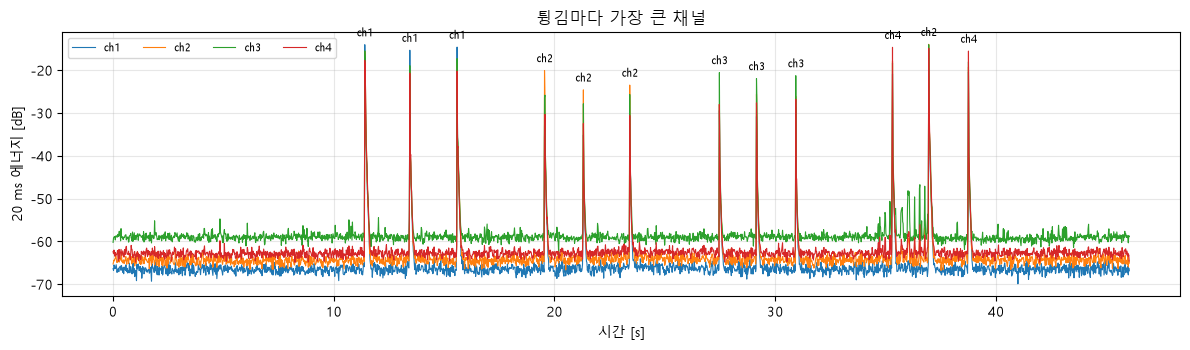

기대 순서 (3번씩): [1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4]
실측 순서         : [np.int64(1), np.int64(1), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(4), np.int64(2), np.int64(4)]
전송: 유실 없음 · CRC 통과 · 클리핑 패킷 9 (튕김을 마이크 바로 옆에서 해 생긴 것인지 시각 확인)


In [5]:
fig, ax = plt.subplots(figsize=(12, 3.6))
for c in range(4):
    ax.plot(t, E[c], lw=0.8, label=f"ch{c + 1}")
for tt, ch, gap, _ in rows:
    ax.annotate(f"ch{ch}", (tt, E[ch - 1][np.argmin(np.abs(t - tt))]), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set_xlabel("시간 [s]"); ax.set_ylabel("20 ms 에너지 [dB]"); ax.set_title("튕김마다 가장 큰 채널"); ax.grid(alpha=.3); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()
exp = [1] * 3 + [2] * 3 + [3] * 3 + [4] * 3
print("기대 순서 (3번씩):", exp)
print("실측 순서         :", seq)
print("전송: 유실", "없음" if S["criteria"]["loss"] and S["criteria"]["ovr"] else "있음", "· CRC", "통과" if S["criteria"]["crc"] else "실패",
      "· 클리핑 패킷", S["packets"]["clip_packets"], "(튕김을 마이크 바로 옆에서 해 생긴 것인지 시각 확인)")

## 5. 게인 (녹음 `ch4_gain`)

1 ~ 1.5 m 스피커의 1 kHz 톤을 들으며 트리머를 맞춘 녹음. 1 s 창마다 채널별 950 ~ 1050 Hz 레벨 [dBFS]을 구하고, **톤이 나온 창 중 마지막 30 s**(맞춘 뒤)의 중앙값을 네 채널 평균과 비교한다. 기준 ±3 dB (`가정`: PHAT는 위상만 써서 게인 차이는 클리핑·바닥 여유만 정한다).

In [6]:
G = "../dumps/stream/ch4_gain"
SG = json.load(open(f"{G}/summary.json", encoding="utf-8"))
g, _ = sf.read(f"{G}/seg_000.wav", dtype="float64"); g = (g - g.mean(0)).T
f = np.fft.rfftfreq(FS, 1 / FS); band = (f >= 950) & (f <= 1050); w = np.hanning(FS)
L = np.array([[10 * np.log10(2 * np.sum(np.abs(np.fft.rfft(g[c, s:s + FS] * w)) ** 2 * (band)) / (FS * np.sum(w ** 2)) + 1e-20)
               for s in range(0, g.shape[1] - FS + 1, FS)] for c in range(4)])
on = np.flatnonzero(L.mean(0) > L.mean(0).max() - 6)          # 1 kHz 톤이 나온 창 (네 채널 평균이 최고값 6 dB 안)
use = on[on >= on.max() - 30]                                  # 그중 마지막 30 s (맞춘 뒤)
last = np.median(L[:, use], axis=1); dev = last - last.mean()
print(f"톤이 나온 창 {len(on)}개 중 마지막 30 s의 {len(use)}개 사용 ({use.min()} ~ {use.max() + 1} s)")
print(f"{g.shape[1] / FS:.1f} s · 클리핑 패킷 {SG['packets']['clip_packets']} · 유실 {'없음' if SG['criteria']['loss'] else '있음'}")
print("1 kHz 레벨, 사용한 창 중앙값 [dBFS]:", np.round(last, 1))
print("네 채널 평균과 차이 [dB]           :", np.round(dev, 1), "→", "모두 ±3 dB 안" if np.all(np.abs(dev) <= 3) else "±3 dB 밖 채널 있음")
print("사용한 창의 채널별 흔들림 (p90 − p10) [dB]:", np.round(np.percentile(L[:, use], 90, axis=1) - np.percentile(L[:, use], 10, axis=1), 1))
print("채널 차이 ch4 − ch1~3 평균, 창마다 p10 ~ p90 [dB]:", np.round(np.percentile(L[3, use] - L[:3, use].mean(0), [10, 90]), 1))

톤이 나온 창 18개 중 마지막 30 s의 18개 사용 (48 ~ 73 s)
82.8 s · 클리핑 패킷 0 · 유실 없음
1 kHz 레벨, 사용한 창 중앙값 [dBFS]: [-35.8 -35.9 -35.9 -40.7]
네 채널 평균과 차이 [dB]           : [ 1.3  1.2  1.2 -3.7] → ±3 dB 밖 채널 있음
사용한 창의 채널별 흔들림 (p90 − p10) [dB]: [5.4 5.1 4.7 3.8]
채널 차이 ch4 − ch1~3 평균, 창마다 p10 ~ p90 [dB]: [-6.5 -3. ]
